# 02 — Price exploration

What a battery is actually trading into, from the cleaned parquet. Three questions:

1. How much spread is there, and is it widening or narrowing?
2. How much of the spread survives the move from five-minute clearing prices to the thirty-minute price energy actually settles on?
3. How large are the FCESS markets relative to energy?

Question 2 matters most. Energy is settled on the Reference Trading Price (ESM Rules 9.9.4), so any spread that exists only *within* a half hour is unavailable to a battery no matter how fast it is.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if str(Path.cwd().parent) not in sys.path:
    sys.path.insert(0, str(Path.cwd().parent))

from src import data, viz
from src.model import SERVICES

viz.use_style()
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

prices = data.load_prices()
prices["year"] = prices["trading_date"].dt.year
print(f"{len(prices):,} dispatch intervals over {prices['trading_date'].nunique():,} trading days")
print(f"{prices['trading_date'].min().date()} to {prices['trading_date'].max().date()}")

324,850 dispatch intervals over 1,128 trading days
2023-10-01 to 2026-11-01


## Price levels by year

2023 covers October to December only and 2026 runs to the most recent complete trading day, so neither is a full year. Like-for-like comparisons come later.

In [2]:
by_year = prices.groupby("year").agg(
    days=("trading_date", "nunique"),
    mean_5min=(data.CLEARING_PRICE_COLUMN, "mean"),
    mean_settlement=(data.SETTLEMENT_PRICE_COLUMN, "mean"),
    min_5min=(data.CLEARING_PRICE_COLUMN, "min"),
    max_5min=(data.CLEARING_PRICE_COLUMN, "max"),
    negative_share=(data.CLEARING_PRICE_COLUMN, lambda s: (s < 0).mean()),
)
by_year.round(2)

,days,mean_5min,mean_settlement,min_5min,max_5min,negative_share
year,,,,,,
2023,92,83.63,83.63,-1000.00,738.0,0.24
2024,366,79.35,79.35,-1000.00,738.0,0.25
2025,365,87.69,87.69,-208.20,1100.0,0.05
2026,305,108.05,108.05,-43.01,1000.0,0.01


## Daily spread, five-minute against thirty-minute

Daily spread is the highest price of the trading day less the lowest. Computed on the five-minute clearing price it is an upper bound no battery can reach; computed on the settlement price it is what is actually available.

In [3]:
daily = prices.groupby("trading_date").agg(
    spread_5min=(data.CLEARING_PRICE_COLUMN, lambda s: s.max() - s.min()),
    spread_settlement=(data.SETTLEMENT_PRICE_COLUMN, lambda s: s.max() - s.min()),
)
daily["year"] = daily.index.year
daily["retained"] = daily["spread_settlement"] / daily["spread_5min"]

spread_summary = daily.groupby("year").agg(
    median_spread_5min=("spread_5min", "median"),
    median_spread_settlement=("spread_settlement", "median"),
    mean_spread_settlement=("spread_settlement", "mean"),
    p90_spread_settlement=("spread_settlement", lambda s: s.quantile(0.9)),
    median_retained=("retained", "median"),
)
spread_summary.round(2)

,median_spread_5min,median_spread_settlement,mean_spread_settlement,p90_spread_settlement,median_retained
year,,,,,
2023,795.00,671.59,597.76,807.05,0.86
2024,791.73,576.98,568.77,906.26,0.77
2025,206.87,145.39,194.49,353.67,0.67
2026,120.63,90.93,116.70,215.77,0.81


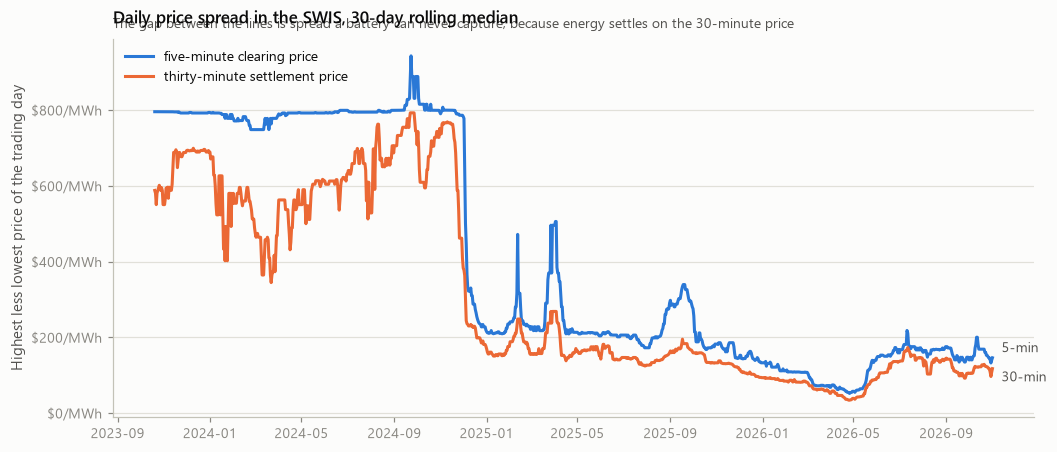

In [4]:
fig, ax = viz.figure(9.5, 4.0)

rolling = daily[["spread_5min", "spread_settlement"]].rolling(30, min_periods=20).median()
ax.plot(rolling.index, rolling["spread_5min"], color=viz.SERIES[0], label="five-minute clearing price")
ax.plot(
    rolling.index,
    rolling["spread_settlement"],
    color=viz.SERIES[1],
    label="thirty-minute settlement price",
)

last = rolling.dropna().iloc[-1]
viz.label_last(ax, rolling.index[-1], last["spread_5min"], "5-min", viz.SERIES[0], offset=6)
viz.label_last(ax, rolling.index[-1], last["spread_settlement"], "30-min", viz.SERIES[1], offset=-6)

viz.money(ax, unit="/MWh")
viz.finish(
    ax,
    "Daily price spread in the SWIS, 30-day rolling median",
    subtitle="The gap between the lines is spread a battery can never capture, because energy settles on the 30-minute price",
    ylabel="Highest less lowest price of the trading day",
)
ax.legend(loc="upper left")
plt.show()

## Average shape of the trading day

Averaged by position in the trading day, which starts at 08:00 AWST. The shape, not the level, is what a battery earns from.

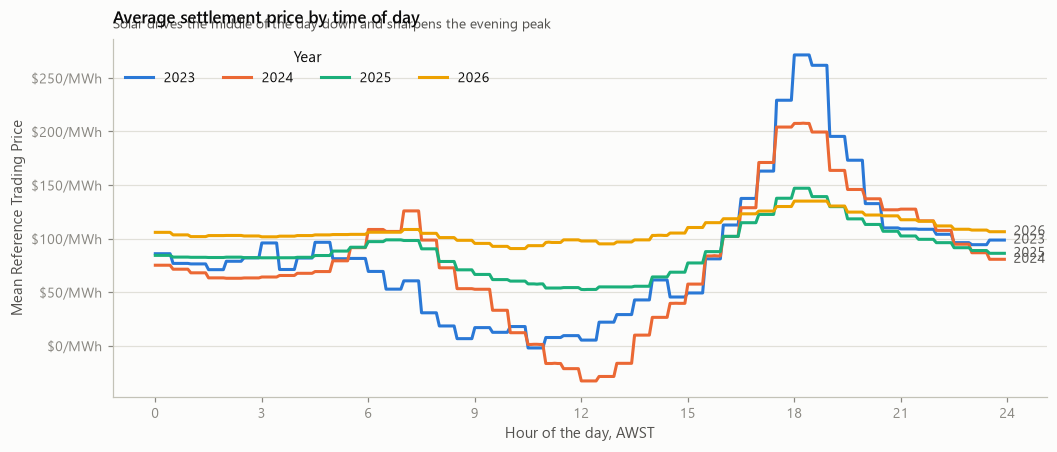

In [5]:
prices["clock"] = prices["interval_start"].dt.hour + prices["interval_start"].dt.minute / 60
shape = prices.pivot_table(
    index="clock", columns="year", values=data.SETTLEMENT_PRICE_COLUMN, aggfunc="mean"
)

fig, ax = viz.figure(9.5, 4.0)
for slot, year in enumerate(shape.columns):
    ax.plot(shape.index, shape[year], color=viz.SERIES[slot], label=str(year))
    viz.label_last(ax, shape.index[-1], shape[year].iloc[-1], str(year), viz.SERIES[slot])

ax.set_xticks(range(0, 25, 3))
ax.set_xlabel("Hour of the day, AWST")
viz.money(ax, unit="/MWh")
viz.finish(
    ax,
    "Average settlement price by time of day",
    subtitle="Solar drives the middle of the day down and sharpens the evening peak",
    ylabel="Mean Reference Trading Price",
)
ax.legend(loc="upper left", title="Year", ncols=4)
plt.show()

## How concentrated is the money?

If most of the available spread sits in a handful of days, a strategy without foresight will miss it, and the capture rate will be low however good the average day looks.

In [6]:
concentration = []
for year, group in daily.groupby("year"):
    ordered = group["spread_settlement"].sort_values(ascending=False)
    total = ordered.sum()
    concentration.append(
        {
            "year": year,
            "days": len(ordered),
            "top_1pct_share": ordered.head(max(1, len(ordered) // 100)).sum() / total,
            "top_5pct_share": ordered.head(max(1, len(ordered) // 20)).sum() / total,
            "top_10pct_share": ordered.head(max(1, len(ordered) // 10)).sum() / total,
        }
    )
pd.DataFrame(concentration).set_index("year").round(3)

,days,top_1pct_share,top_5pct_share,top_10pct_share
year,,,,
2023,92,0.024,0.082,0.159
2024,366,0.024,0.122,0.217
2025,365,0.043,0.183,0.286
2026,305,0.073,0.169,0.271


## FCESS prices

Five services, each cleared every five minutes. Mean prices are modest, but a battery can be enabled for several at once, and enablement is paid on capacity held available rather than on energy delivered.

In [7]:
fcess_columns = list(data.FCESS_PRICE_COLUMNS)
fcess_summary = prices.groupby("year")[fcess_columns].mean().T
fcess_summary.index = [c.replace("_price", "") for c in fcess_summary.index]
fcess_summary.round(2)

year,2023,2024,2025,2026
contingency_raise,43.43,42.24,9.72,1.04
contingency_lower,82.09,45.14,18.84,2.24
regulation_raise,41.00,28.77,7.73,1.21
regulation_lower,59.53,54.54,9.91,0.85
rocof,0.01,0.00,0.00,0.00


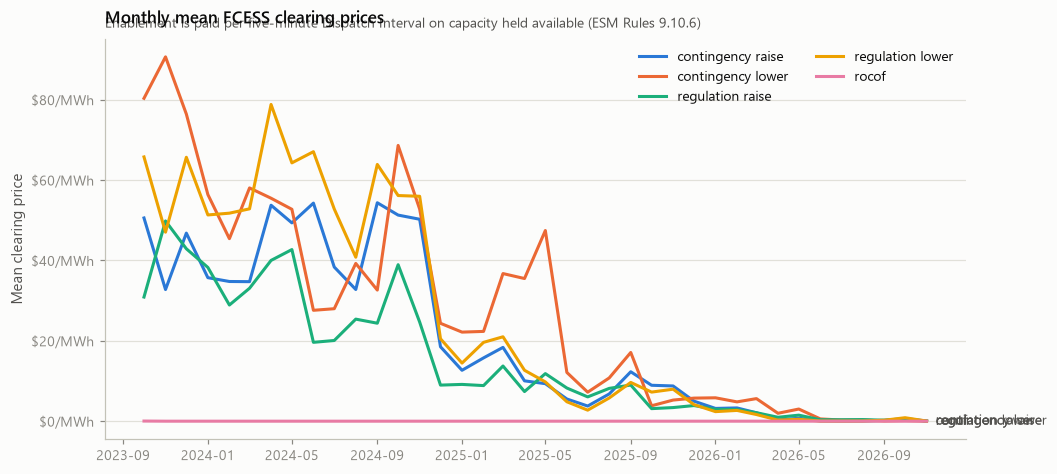

In [8]:
monthly = prices.set_index("interval_start")[fcess_columns].resample("MS").mean()

fig, ax = viz.figure(9.5, 4.2)
for slot, column in enumerate(fcess_columns):
    name = column.replace("_price", "").replace("_", " ")
    ax.plot(monthly.index, monthly[column], color=viz.SERIES[slot], label=name)
    viz.label_last(ax, monthly.index[-1], monthly[column].iloc[-1], name, viz.SERIES[slot])

viz.money(ax, unit="/MWh")
viz.finish(
    ax,
    "Monthly mean FCESS clearing prices",
    subtitle="Enablement is paid per five-minute Dispatch Interval on capacity held available (ESM Rules 9.10.6)",
    ylabel="Mean clearing price",
)
ax.legend(loc="upper right", ncols=2)
plt.show()

## A rough sense of scale

Before any optimisation: what would 100 MW earn from simply being available for one FCESS service all year, against what a perfect two-price-per-day energy trade would earn? This is only an order-of-magnitude check that the FCESS side deserves to be in the model at all.

In [9]:
DT = 5 / 60
full_years = [2024, 2025]
scale = []

for year in full_years:
    year_prices = prices[prices["year"] == year]
    row = {"year": year}
    for column in fcess_columns:
        row[column.replace("_price", "")] = year_prices[column].sum() * DT * 100 / 1e6
    # A single perfect charge-and-discharge of a 2-hour 100 MW battery each day.
    day_spread = year_prices.groupby("trading_date")[data.SETTLEMENT_PRICE_COLUMN].agg(
        lambda s: s.nlargest(24).mean() - s.nsmallest(24).mean()
    )
    row["energy_one_cycle_per_day"] = (day_spread * 200).sum() / 1e6
    scale.append(row)

pd.DataFrame(scale).set_index("year").round(2)

,contingency_raise,contingency_lower,regulation_raise,regulation_lower,rocof,energy_one_cycle_per_day
year,,,,,,
2024,37.10,39.65,25.27,47.91,0.0,29.71
2025,8.51,16.50,6.77,8.68,0.0,10.17


Figures are $ million per year for a 100 MW battery. The FCESS columns assume continuous enablement at 100 MW in that one service, which no battery can do for all five at once, so they are upper bounds taken one service at a time. The energy column assumes a perfect single two-hour cycle each day with no efficiency loss.

Both sides are material, which is why the dispatch model co-optimises them rather than treating FCESS as an add-on.